# Importing

In [52]:
# %% Cell 1: Imports
import pandas as pd
import numpy as np
from darts import TimeSeries

seed = 24775456

import matplotlib.pyplot as plt
import datetime as dt

In [53]:
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
colors = {"pre": "tab:blue", "during": "tab:orange", "post": "tab:green"}  # same as XGB notebook plots

# Load Data 

In [54]:
# %% Cell 2: Load Data
def loadData():
    df = pd.read_parquet("gafanha.parquet")
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.round("h")
    return (
        df.pivot_table(index="timestamp", columns="collection", values="value", aggfunc="median")
        .asfreq("h")
        .loc[:"2023-12-31 23:00"]
        .drop(columns=["Radiation", "Precipitation"])  # only exist in 2024
        .reset_index()
    )

df = loadData()

In [55]:
# %% Cell 4: Force daily, median and fill in missing values with darts package
from darts.utils.missing_values import fill_missing_values
daily = df.set_index("timestamp").resample("D").median().asfreq("D")
print(daily.count())

# European AQI breakpoints per pollutant
aqi_bins = {
    "PM25": [-np.inf, 10, 20, 25, 50, np.inf],
    "PM10": [-np.inf, 20, 35, 50, 100, np.inf],
    "NO2":  [-np.inf, 40, 100, 200, 400, np.inf],
    "O3":   [-np.inf, 80, 100, 180, 240, np.inf],
    "SO2":  [-np.inf, 100, 200, 350, 500, np.inf],
}
def sub_index(df):
    return pd.concat([pd.cut(df[p], bins=b, labels=[1, 2, 3, 4, 5]).astype(float) for p, b in aqi_bins.items()], axis=1)

# raw observed data only: for the coverage / dominant-pollutant checks, not for modelling
sub_idx = sub_index(daily)
dominant = sub_idx.dropna(how="all").idxmax(axis=1)

daily.index = daily.index.tz_localize(None)
series = fill_missing_values(TimeSeries.from_dataframe(daily, freq="D"))

collection
Benzene          2616
CO               2644
NO               2613
NO2              2613
NOx              2613
O3               2642
PM10             2632
PM25             2626
Particles        2626
SO2              2626
Temperature      2635
WindDirection    2635
WindSpeed        2635
dtype: int64


In [56]:
def summarize(d):
    return pd.DataFrame({
        "n": d.count(), "mean": d.mean(), "median": d.median(), "std": d.std(),
        "min": d.min(), "q25": d.quantile(0.25), "q75": d.quantile(0.75), "max": d.max(),
        "skew": d.skew(), "kurtosis": d.kurt(),
    })

filled = series.to_dataframe()
stats_raw = summarize(daily)
stats_filled = summarize(filled)

print("RAW (before imputation)")
print(stats_raw.round(2))
print("\nFILLED (after imputation)")
print(stats_filled.round(2))
print("\nChange in std (filled - raw)")
print((stats_filled["std"] - stats_raw["std"]).round(3))

RAW (before imputation)
                  n    mean  median    std   min     q25     q75     max  \
collection                                                                 
Benzene        2616    1.64    0.99   1.86  0.00    0.48    2.07   24.60   
CO             2644    0.24    0.20   0.15  0.02    0.15    0.28    1.98   
NO             2613    2.01    1.00   5.16  0.05    0.65    1.80   94.38   
NO2            2613    8.16    6.42   5.90  0.72    3.85   10.62   40.20   
NOx            2613   11.56    8.44  11.70  1.15    5.25   13.73  162.12   
O3             2642   58.25   60.45  21.74  1.68   45.06   73.25  148.40   
PM10           2632   24.86   21.00  15.35  0.49   14.50   31.00  191.50   
PM25           2626   11.06    9.00   8.80  0.00    6.00   13.00  173.00   
Particles      2626   11.06    9.00   8.80  0.00    6.00   13.00  173.00   
SO2            2626    1.54    1.40   0.85  0.10    0.87    2.05    7.30   
Temperature    2635   15.65   15.95   3.60  3.65   13.14   18.30

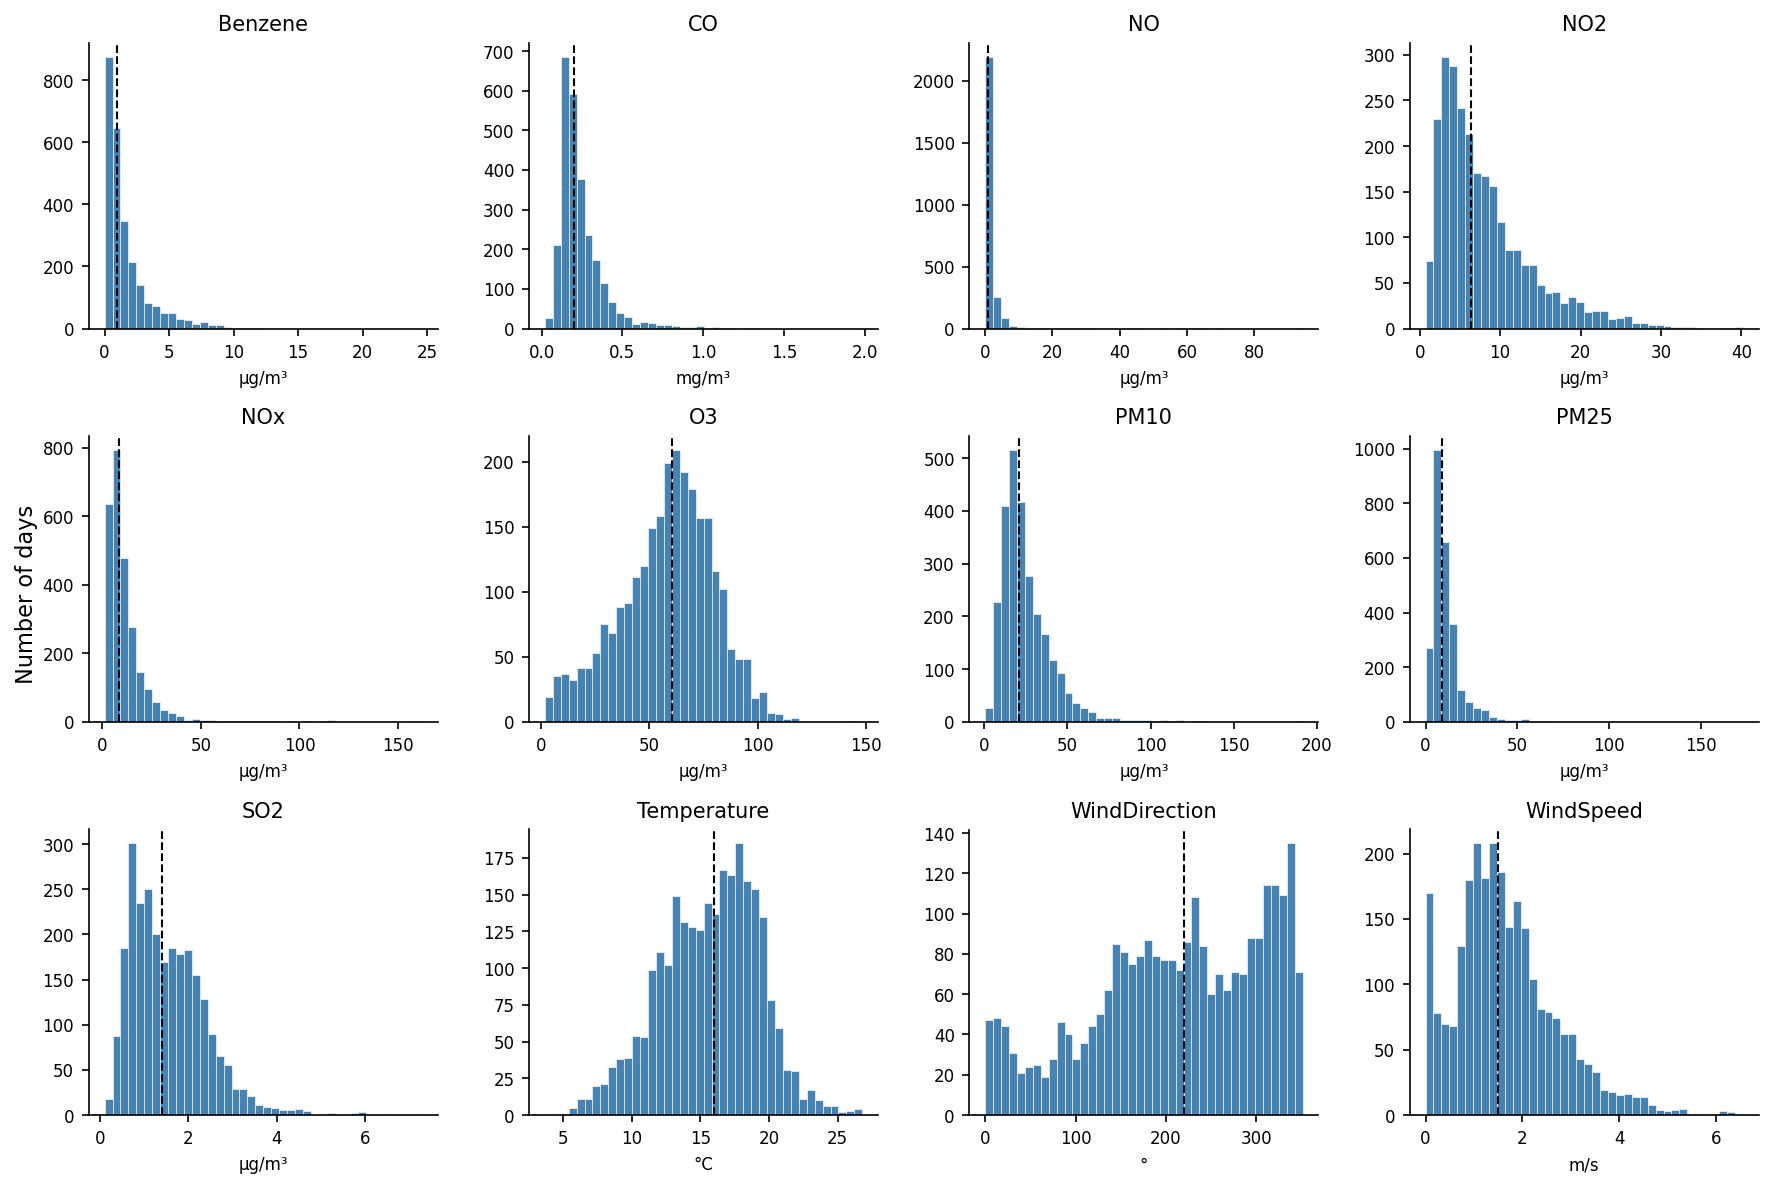

In [57]:
units = {  # check against the `unit` column in gafanha.parquet
    "Benzene": "µg/m³", "CO": "mg/m³", "NO": "µg/m³", "NO2": "µg/m³", "NOx": "µg/m³",
    "O3": "µg/m³", "PM10": "µg/m³", "PM25": "µg/m³", "SO2": "µg/m³",
    "Temperature": "°C", "WindDirection": "°", "WindSpeed": "m/s",
}
cols = [c for c in daily.columns if c != "Particles"]  # identical to PM25

def plot_hist(d, fname):
    fig, axes = plt.subplots(3, 4, figsize=(12, 8))
    for ax, c in zip(axes.flat, cols):
        s = d[c].dropna()
        ax.hist(s, bins=40, color="steelblue", edgecolor="white", linewidth=0.3)
        ax.axvline(s.median(), color="black", ls="--", lw=1)
        ax.set_title(c, fontsize=10)
        ax.set_xlabel(units[c], fontsize=8)
        ax.tick_params(labelsize=8)
    fig.supylabel("Number of days")
    plt.tight_layout()
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

plot_hist(daily, "distributions_raw.png")

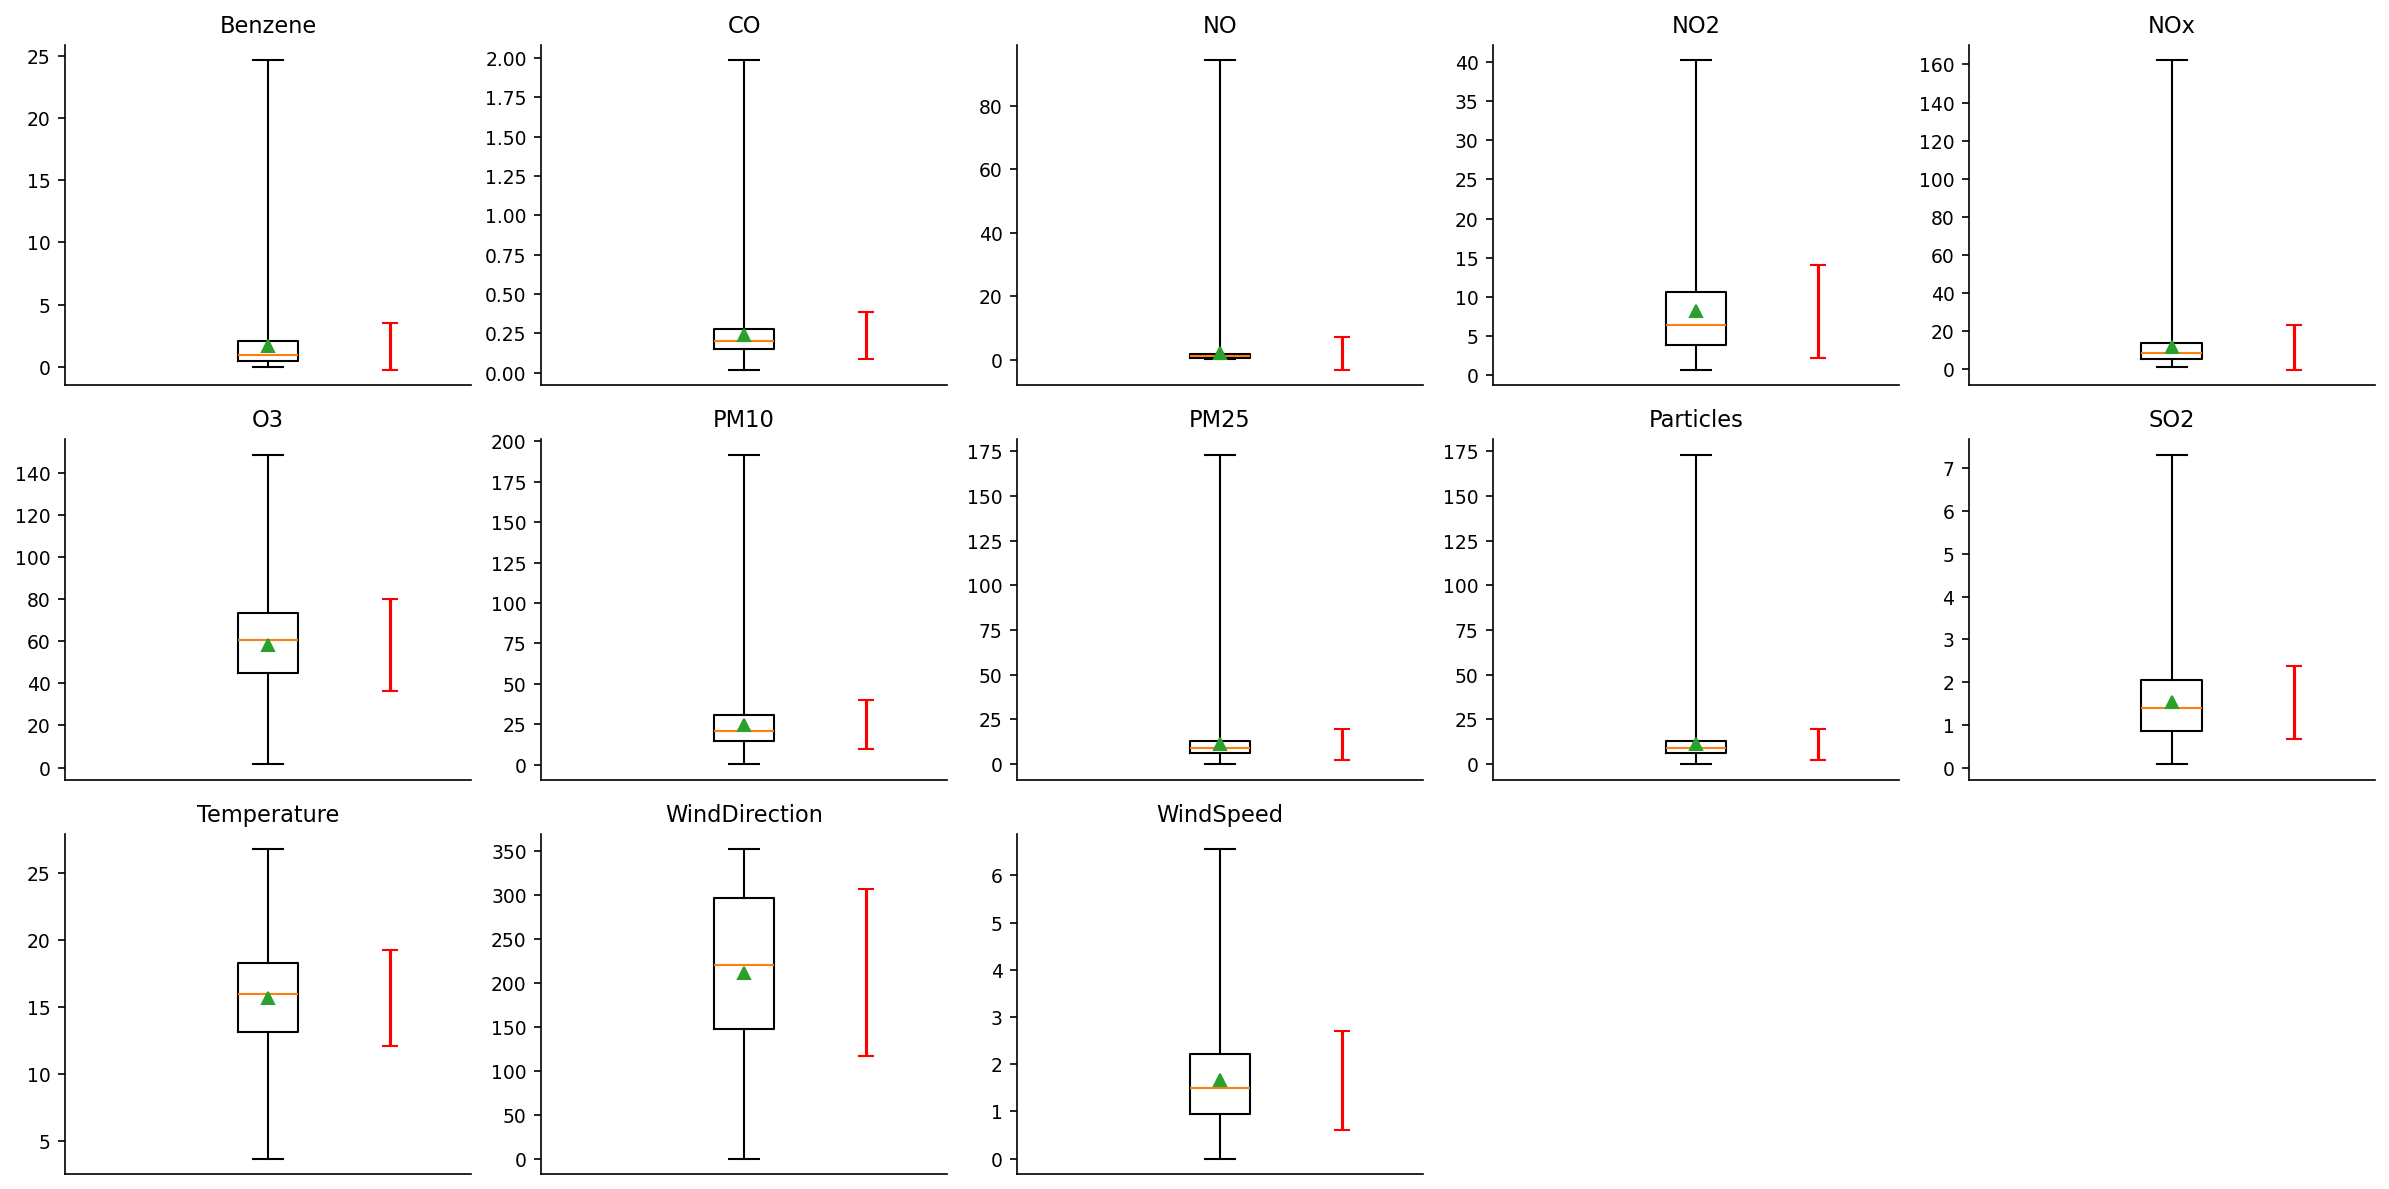

In [58]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, c in zip(axes.flat, daily.columns):
    s = daily[c].dropna()
    ax.boxplot(s, whis=(0, 100), showmeans=True)       # whiskers = min and max
    ax.errorbar(1.3, s.mean(), yerr=s.std(), fmt="none", capsize=4, color="red")
    ax.set_title(c)
    ax.set_xticks([])
for ax in axes.flat[len(daily.columns):]:
    ax.axis("off")                                     # 13 variables, 15 slots
plt.tight_layout()
plt.show()

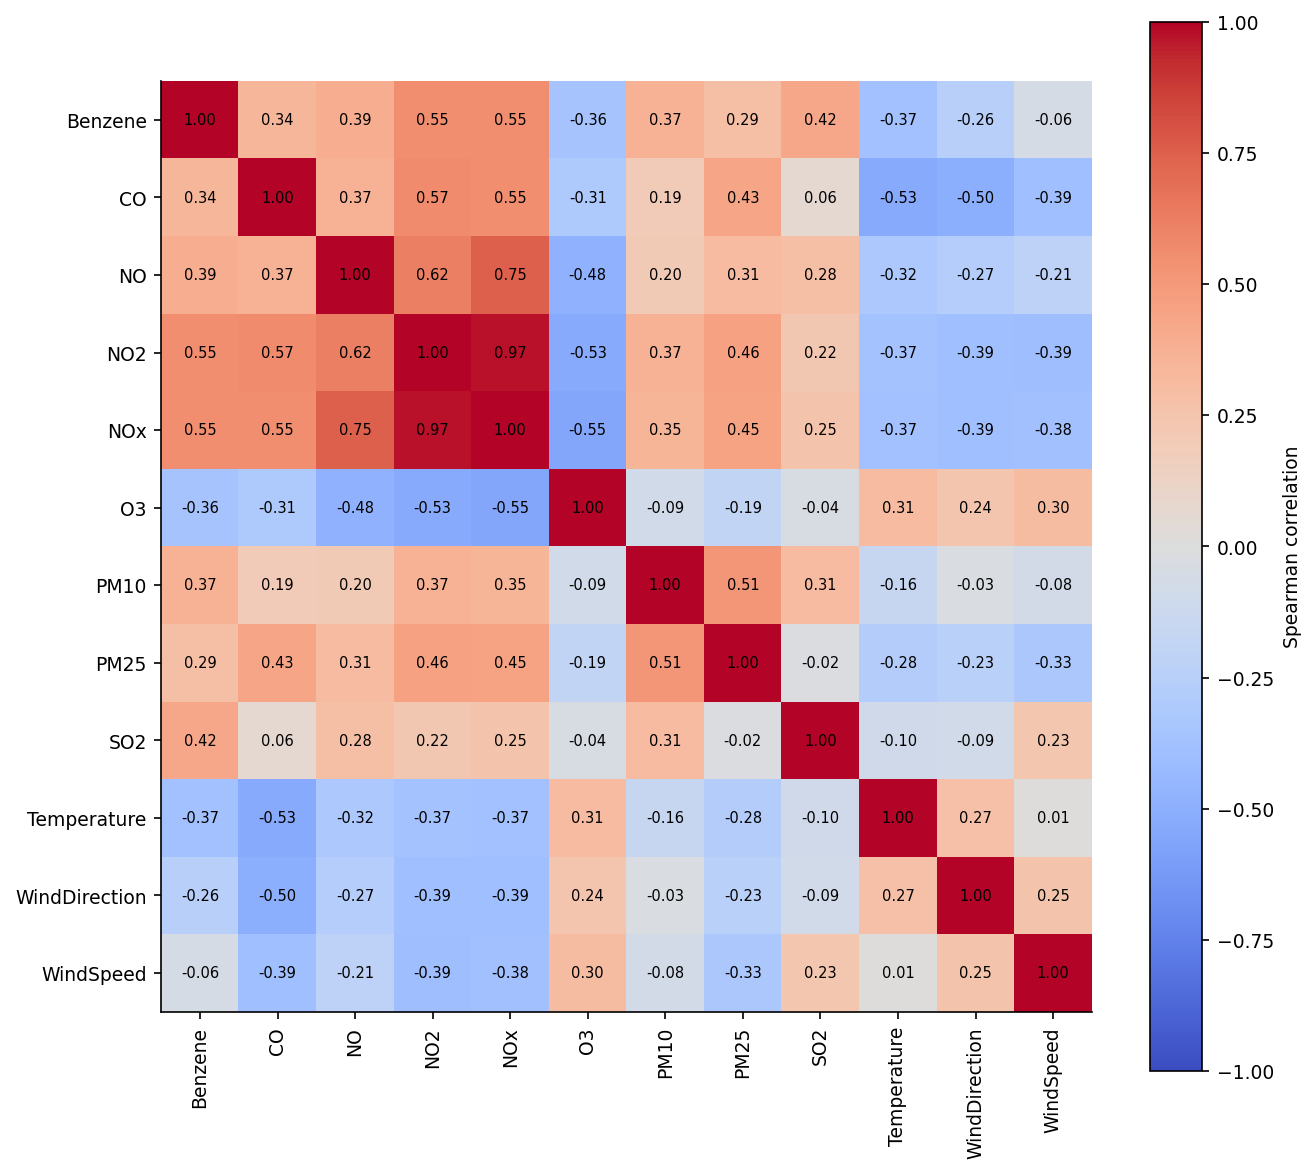

In [59]:
cols = [c for c in daily.columns if c != "Particles"]  # identical to PM25
corr = daily[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="Spearman correlation")
plt.tight_layout()
plt.savefig("correlation.png", dpi=300, bbox_inches="tight")
plt.show()

## **END** ##

## For changes in characteristic (finding 1)

In [60]:
bounds = {"pre":    (None, "2020-02-29"),  
          "during": ("2020-03-01", "2021-04-30"),
          "post":   ("2021-05-01", None)}
pollutants = list(aqi_bins)

In [61]:
period = pd.Series(index=daily.index, dtype=object)
for n, (s, e) in bounds.items():
    period.loc[s:e] = n
order = list(bounds)

print(period.value_counts()[order])
print((daily.isna().groupby(period).mean() * 100).T[order].round(1))

pre       1308
during     426
post       975
Name: count, dtype: int64
               pre  during  post
collection                      
Benzene        6.7     0.7   0.3
CO             4.8     0.5   0.0
NO             5.4     4.0   0.8
NO2            5.4     4.0   0.8
NOx            5.4     4.0   0.8
O3             5.0     0.2   0.0
PM10           4.7     0.5   1.3
PM25           4.7     1.9   1.3
Particles      4.7     1.9   1.3
SO2            5.5     0.2   1.0
Temperature    5.7     0.0   0.0
WindDirection  5.7     0.0   0.0
WindSpeed      5.7     0.0   0.0


In [62]:
from scipy.stats import kruskal

g = daily.groupby(period)
med = g.median().T[order]
iqr = (g.quantile(.75) - g.quantile(.25)).T[order]
kw = pd.Series({c: kruskal(*[daily.loc[period == n, c].dropna() for n in order]).pvalue
                for c in daily.columns}, name="kruskal_p")
print(med.round(2), iqr.round(2), kw.round(4), sep="\n\n")

                  pre  during    post
collection                           
Benzene          1.48    1.56    0.49
CO               0.18    0.20    0.22
NO               1.11    1.45    0.83
NO2              7.26    7.25    5.48
NOx              9.35    9.80    7.03
O3              59.25   61.00   61.65
PM10            27.50   16.50   17.00
PM25             8.00    9.50    9.00
Particles        8.00    9.50    9.00
SO2              1.97    1.50    0.84
Temperature     15.60   15.38   16.60
WindDirection  220.12  221.00  220.50
WindSpeed        1.75    1.60    1.04

                  pre  during    post
collection                           
Benzene          2.24    1.83    0.70
CO               0.13    0.11    0.14
NO               1.37    1.40    0.70
NO2              8.53    5.84    5.60
NOx             10.71    7.69    6.56
O3              30.71   29.25   25.45
PM10            18.50   12.25   10.50
PM25             8.00    5.50    7.00
Particles        8.00    5.50    7.00
SO2        

In [63]:
from matplotlib.patches import Patch

def shade(ax, idx):
    for n, (s, e) in bounds.items():
        ax.axvspan(pd.Timestamp(s) if s else idx[0], pd.Timestamp(e) if e else idx[-1],
                   color=colors[n], alpha=0.15)

period_legend = [Patch(color=colors[n], alpha=0.3, label=n) for n in order]

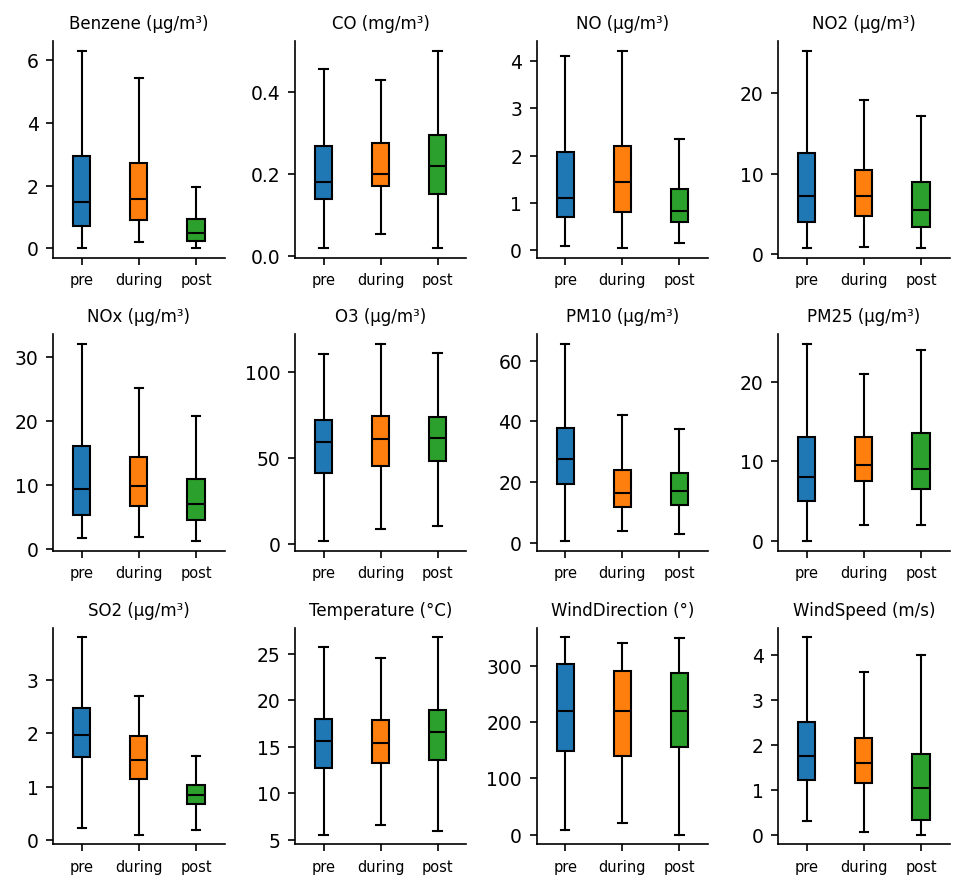

In [64]:
fig, axes = plt.subplots(3, 4, figsize=(6.5, 6))
for ax, c in zip(axes.flat, cols):
    bp = ax.boxplot([daily.loc[period == n, c].dropna() for n in order],
                    patch_artist=True, showfliers=False, medianprops=dict(color="black"))
    for box, n in zip(bp["boxes"], order):
        box.set_facecolor(colors[n])
    ax.set_xticks([1, 2, 3], order, fontsize=7)
    ax.set_title(f"{c} ({units[c]})", fontsize=8)
plt.tight_layout(); plt.savefig("period_boxplots.png"); plt.show()

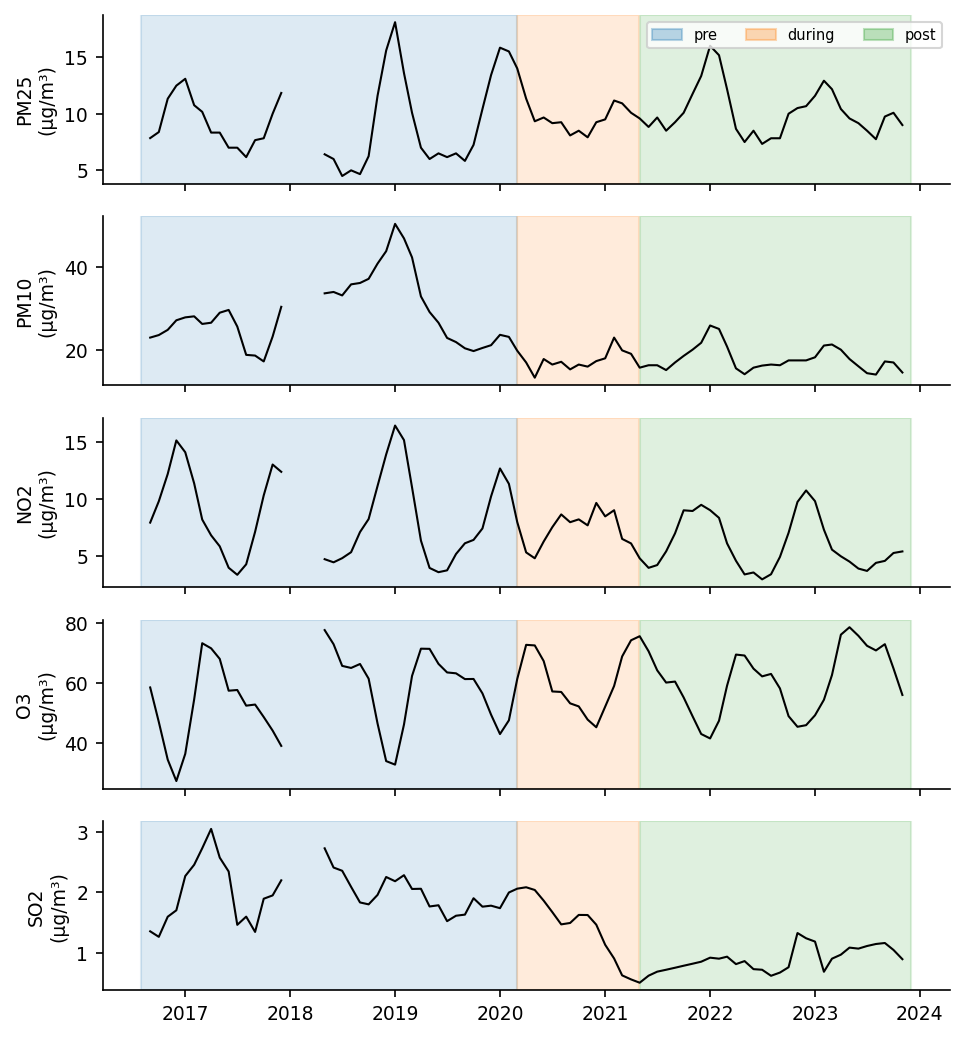

In [65]:
from matplotlib.patches import Patch

m = daily[pollutants].resample("MS").median().rolling(3, center=True).mean()
fig, axes = plt.subplots(len(pollutants), 1, figsize=(6.5, 7), sharex=True)
for ax, p in zip(axes, pollutants):
    ax.plot(m.index, m[p], c="black", lw=1)
    for n, (s, e) in bounds.items():
        ax.axvspan(pd.Timestamp(s) if s else m.index[0], pd.Timestamp(e) if e else m.index[-1],
                   color=colors[n], alpha=0.15)
    ax.set_ylabel(f"{p}\n({units[p]})")
axes[0].legend(handles=[Patch(color=colors[n], alpha=0.3, label=n) for n in order],
               ncol=3, loc="upper right", fontsize=7)
plt.tight_layout(); plt.savefig("period_trend.png"); plt.show()

In [66]:
sub = sub_index(daily)
aqi_obs = sub.max(axis=1)
print((pd.crosstab(aqi_obs, period, normalize="columns")[order] * 100).round(1))

ties = sub.eq(aqi_obs, axis=0).sum(axis=1) > 1
print((ties.groupby(period).mean().reindex(order) * 100).round(1))

col_0   pre  during  post
row_0                    
1.0    22.2    41.3  48.9
2.0    43.7    45.5  39.8
3.0    21.1     8.5   5.9
4.0    11.4     4.0   4.9
5.0     1.6     0.7   0.4
pre       40.1
during    67.8
post      74.9
dtype: float64


In [67]:
print({n: round(1.96 / np.sqrt((period == n).sum() - 3), 3) for n in order})

{'pre': np.float64(0.054), 'during': np.float64(0.095), 'post': np.float64(0.063)}


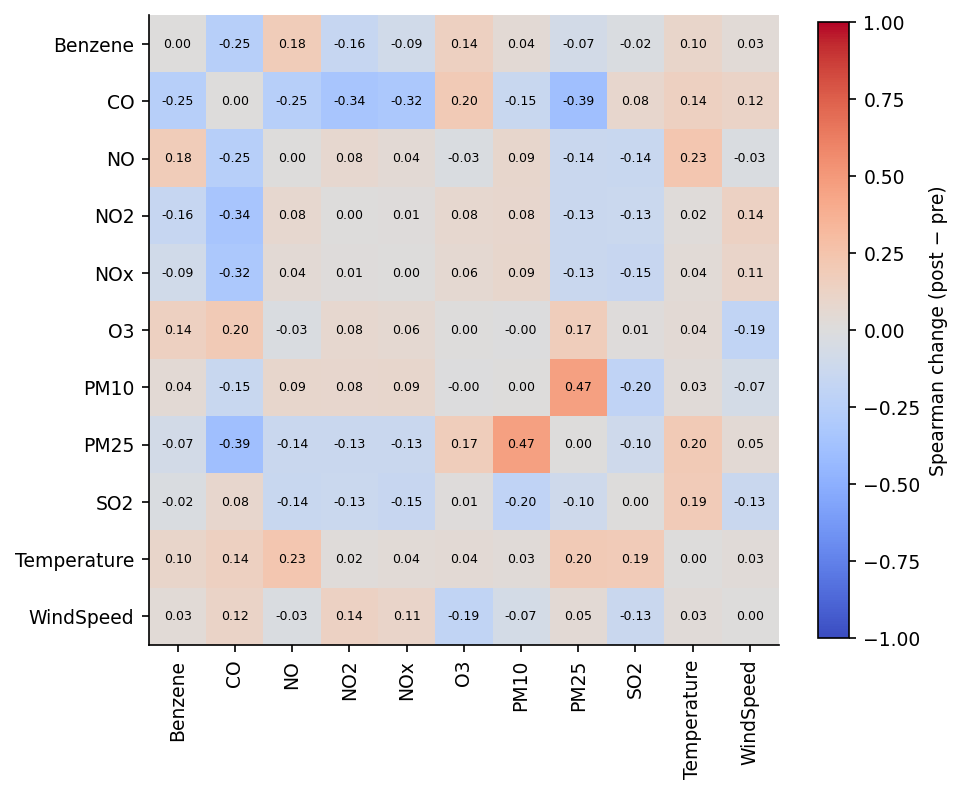

In [68]:
gcols = [c for c in cols if c != "WindDirection"]   # angle, rank correlation meaningless
d = daily[gcols]
diff = d[period == "post"].corr(method="spearman") - d[period == "pre"].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(diff, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(gcols)), gcols, rotation=90); ax.set_yticks(range(len(gcols)), gcols)
for i in range(len(gcols)):
    for j in range(len(gcols)):
        v = diff.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, label="Spearman change (post − pre)", shrink=0.8)
plt.tight_layout(); plt.savefig("period_corr_diff.png"); plt.show()

## AQI

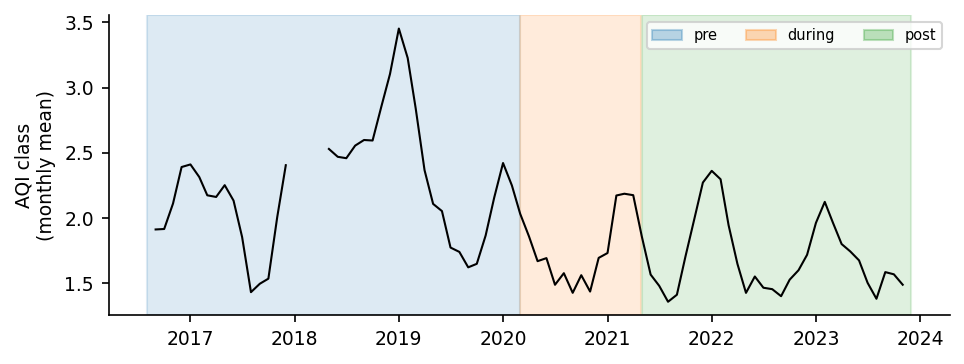

In [69]:
aqi_m = aqi_obs.resample("MS").mean().rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(6.5, 2.5))
ax.plot(aqi_m.index, aqi_m, c="black", lw=1)
shade(ax, aqi_m.index)
ax.set_ylabel("AQI class\n(monthly mean)")
ax.legend(handles=period_legend, ncol=3, loc="upper right", fontsize=7)
plt.tight_layout(); plt.savefig("aqi_trend.png"); plt.show()

In [70]:
ac = pd.DataFrame({n: {k: aqi_obs[period == n].autocorr(k) for k in (1, 7, 30)} for n in order})
print(ac.round(2))

     pre  during  post
1   0.60    0.58  0.53
7   0.27    0.17  0.09
30  0.19    0.07  0.09


In [71]:
x = {n: aqi_obs[period == n] for n in order}
print(pd.DataFrame({n: s.iloc[int(len(s) * .8):].describe() for n, s in x.items()}).round(2))

          pre  during    post
count  260.00   86.00  195.00
mean     1.95    2.22    1.45
std      1.00    0.93    0.55
min      1.00    1.00    1.00
25%      1.00    2.00    1.00
50%      2.00    2.00    1.00
75%      2.00    3.00    2.00
max      5.00    5.00    3.00


In [72]:
chg = (med[["during", "post"]].div(med["pre"], axis=0) - 1) * 100
print(chg.round(1))

               during  post
collection                 
Benzene           5.4 -67.1
CO               11.1  22.2
NO               30.6 -25.2
NO2              -0.2 -24.6
NOx               4.8 -24.8
O3                3.0   4.1
PM10            -40.0 -38.2
PM25             18.8  12.5
Particles        18.8  12.5
SO2             -23.9 -57.4
Temperature      -1.4   6.4
WindDirection     0.4   0.2
WindSpeed        -8.7 -40.6


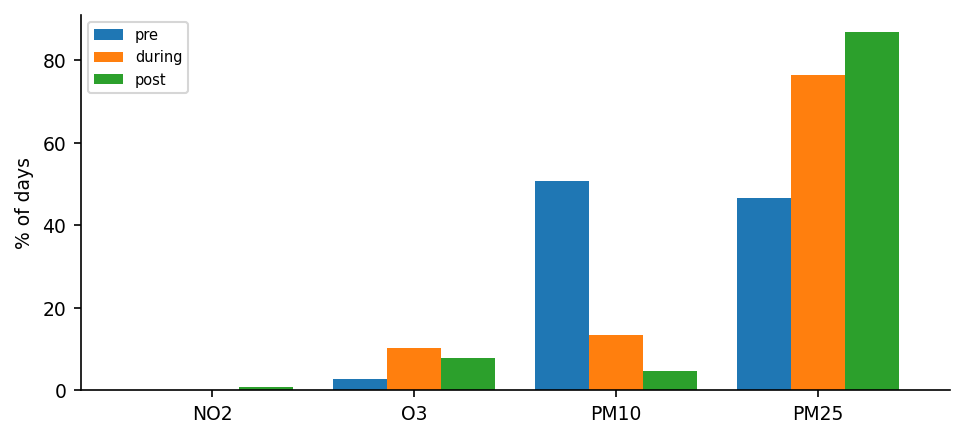

In [73]:
dom = sub.dropna(how="all").idxmax(axis=1)
share = pd.crosstab(period[dom.index], dom, normalize="index").reindex(order) * 100

ax = share.T.plot.bar(figsize=(6.5, 3), color=[colors[n] for n in order], width=0.8)
ax.set_xlabel(""); ax.set_ylabel("% of days")
ax.legend(title=None, fontsize=7)
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("dominant_pollutant.png"); plt.show()